# HW5 — Overland Flow and Open-Channel Hydraulics

Selected computational coursework from CEE 306: Hydrology — Water and Climate, Princeton University (Spring 2026). Code, answers, and saved results are retained from the original submission; assignment instructions have been removed for portfolio presentation.

## Overland-flow simulation

In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

## Kinematic-wave model

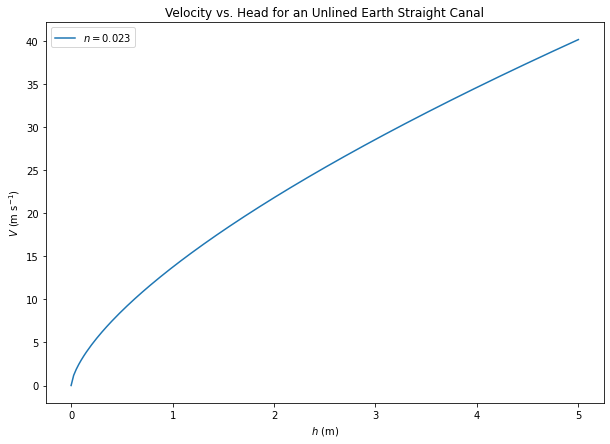

In [2]:
# let's see the how the velocity changes over different h values
# let's say S_0 is constant at a slope of 0.1
# and n = 0.023 for unlined earth straight canal

# first define function to obtain velocity
def mannings(S_0,h,n):
    V = np.sqrt(S_0)*h**(2./3.)/n
    return V

# array of values for h
# we want to plot how V changes as h changes from 0 to 5 meters
h_array = np.linspace(0,5,200)

# calculate v using function above for constant S_0 and n
V = mannings(0.1,h_array, 0.023)

# plot velocity vs head 
fig, ax = plt.subplots(figsize = (10,7))
ax.plot(h_array, V,label=r'$n=0.023$')
ax.set_xlabel(r'$h$'+' (m)')
ax.set_ylabel(r'$V$'+' (m s'+r'$^{-1}$'+')')
ax.set_title('Velocity vs. Head for an Unlined Earth Straight Canal')
ax.legend()

## Numerical solution

In [3]:
def run_num(L,s0,n,rd,rr,dt,dx):
    # run_num is short for runoff numerical solution
    # the inputs are hillsope length (L), slope (s0), Manning's n (n), rain duration (rd), rain rate (rr), 
    # time step (dt), and space step (dx) which is the distance between two simulated spots on the hill
    
    # define simulation time (90 minutes in seconds)
    st = 90*60
    
    # make 'lengths' for space (i) and time (j)
    time = 1+int(st/dt) 
    space = 1+int(L/dx)
    
    # initialize the time array
    t = [0]
    
    # create a 2D space-time array
    h = np.zeros([space,time])
    
    # create 1D array for runoff in L^2/t, missing width of stream
    runoff = np.zeros(time)
    
    # loop through the discretized equation
    for j in range(0,(time-1)):
        
        # append time (in seconds)
        t.append((j+1)*dt)
        
        # for this timestep, update every new value in space
        for i in range(0,(space-1)):
            
            # if no rain, rain input is 0
            if j*dt > rd:
                w = 0
                
            # if still raining, rain rate times the timestep
            else:
                w = rr*dt
            
            # calculate the adjacent head value in time and space using equation
            h[i+1,j+1] = h[i+1,j] + w - ((dt*math.sqrt(s0))*(h[i+1,j]**(5/3) - h[i,j]**(5/3))/(dx*n))
        
        # calculate the runoff at the farthest head location
        runoff[j] = ((math.sqrt(s0)*(h[(space-1),j+1])**(5/3))/n)
        
    return runoff, h, t

### Simulated runoff hydrographs

In [4]:
# get head distribution and runoff with the following values:

# length (m) and slope (m/m) of domain
L = 100
s0 = 0.01

# mannings coefficient (s/(m^(1/3)))
n = 0.02

# rainfall duration (s) and rate (m/s)
rd = 1500
rr = 0.0000027

# dt (s) and dx (m)
dt = 0.3
dx = 10

runoff_1, head_1, time = run_num(L,s0,n,rd,rr,dt,dx)

# what if the slope is steeper?
s0_2 = 0.05

runoff_2, head_2, time = run_num(L,s0_2,n,rd,rr,dt,dx)

# what if the rain rate is more intense?
rr_3 = 0.0000035

runoff_3, head_3, time = run_num(L,s0,n,rd,rr_3,dt,dx)

Text(0.5, 0, 'Time [$s$]')

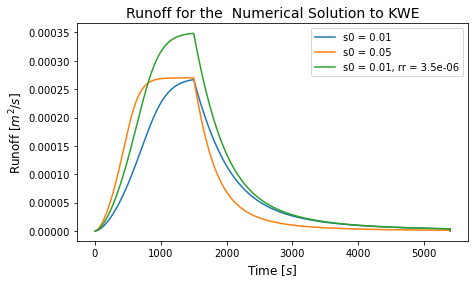

In [5]:
fig, ax = plt.subplots(figsize=(7,4))

ax.plot(time,runoff_1,label= f's0 = {s0}')
ax.plot(time,runoff_2,label= f's0 = {s0_2}')
ax.plot(time,runoff_3,label= f's0 = {s0}, rr = {rr_3}')
ax.legend()
ax.set_title('Runoff for the  Numerical Solution to KWE',fontsize=14)
ax.set_ylabel('Runoff [$m^2/s$]',fontsize=12)
ax.set_xlabel('Time [$s$]',fontsize=12)

### Water-depth profiles

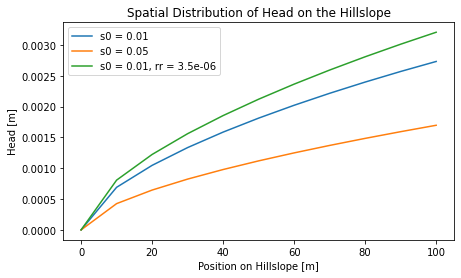

In [6]:
# make an array to represent the length along the hillslope
space = np.arange(0, L+dx, dx)

t_app_ind = int(rd/dt)

# plot
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(space, head_1[:,t_app_ind],label= f's0 = {s0}')
ax.plot(space, head_2[:,t_app_ind],label= f's0 = {s0_2}')
ax.plot(space, head_3[:,t_app_ind],label= f's0 = {s0}, rr = {rr_3}')
ax.set_ylabel('Head [m]')
ax.set_xlabel('Position on Hillslope [m]')
ax.set_title('Spatial Distribution of Head on the Hillslope')
ax.legend()

## Open-channel flow

### Q1 — Froude number and flow regime

`Q1.1 The Froude number describes the balance (ratio) between a motion of water and gravitational forces. As formula suggests, if Fr value is less than enough, it means gL term is larger, implying gravity is dominating factor and flow is slow & deep. Water can even travel upstream. If Fr > 1, it means V factor dominates, implying inertia & motion of water itself matter more. Flow is fast and shallow, and it is usually downstream. If Fr = 1 condition is rare in nature and mostly can be produced in labs, but it just shows a balance and transitional face from subcritical (<1) to supercritical (>1) flow. Simply Fr tells us whether water is calm or rapid. `

`Q1.2 I used the code below since calculating there was easier. As the results show, both River 1 and River 2 are subcritical as Froude numbers are below 1: 0.29 and 0.86 respectively. `

In [7]:
import math

b1 = 12 #m
h1 = 5 #m
b2 = 4 #m
h2 = 5 #m
g = 9.81 #m / s^2
Q = 120 #cms

#Two formulas we use are A = b x h, V = Q / A

A1 = b1 * h1
V1 = Q / A1
L1 = h1 

Fr_1 = V1 / math.sqrt(g * L1)
print (f'Froude number for River 1 is: {Fr_1}')


A2 = b2 * h2
V2 = Q / A2
L2 = h2 

Fr_2 = V2 / math.sqrt(g * L2)
print (f'Froude number for River 1 is: {Fr_2}')

if Fr_1 < 1.00:
    print ('River 1 is subcritical')
else:
    print ('River 1 is supercritical')
if Fr_2 < 1.00:
    print ('River 2 is subcritical')
else:
    print ('River 2 is supercritical')

Froude number for River 1 is: 0.2855686245854129
Froude number for River 1 is: 0.8567058737562386
River 1 is subcritical
River 2 is subcritical


`Q1.3 While River 2 is also subcritical, it is very close to 1. River 2 is faster, and near critical flow. River 1 is slower, deeper, and clearly a subcritical flow. If River 2 is diverted into River 1, flow must adjust from fast flow into slower, more subcritical flow. It will cause a hydraulic jump because there is quite a difference between their froude numbers. Physically, water suddenly slows down, depth increases, flow becomes more stable downstream, and energy gets transferred into extreme turbulence during hydraulic jump.`

### Q2 — Stage–discharge rating curve

In [8]:
# don't change anything in this cell, but make sure you understand it

start_date = '2021-05-01'
end_date = '2021-07-01'

# import 15-minute streamflow and gage data #
url = 'https://nwis.waterdata.usgs.gov/usa/nwis/uv/?cb_00060=on&cb_00065=on&format=rdb&site_no=01401000&period=&begin_date='+start_date+'&end_date='+end_date
#print(url)
StonyBrook = pd.read_csv(url, sep='\t', skiprows=32)
StonyBrook.columns = ['agency','site','datetime','timezone','discharge (cfs)','discharge approval','gage height (ft)','gage height approval']
#print(StonyBrook.head())

Text(0.5, 0, 'Time')

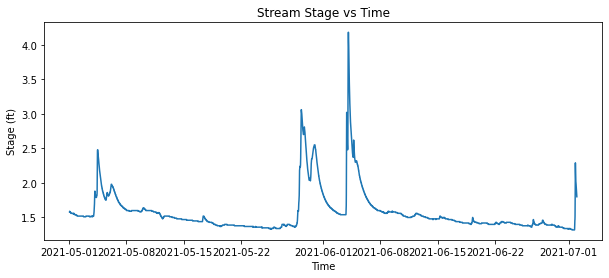

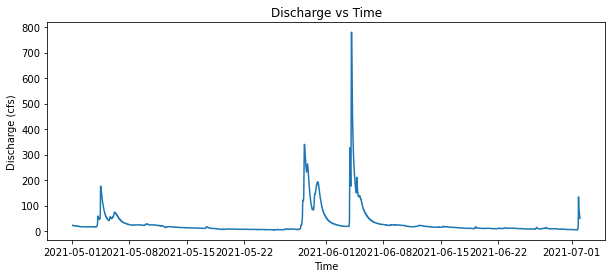

In [9]:
## Q2.1 code here ##

StonyBrook['datetime'] = pd.to_datetime(StonyBrook['datetime'])

time = StonyBrook['datetime']
stage = StonyBrook['gage height (ft)']
discharge = StonyBrook['discharge (cfs)']

# Plot A - Stage vs Time
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(time, stage)
ax.set_title('Stream Stage vs Time')
ax.set_ylabel('Stage (ft)')
ax.set_xlabel('Time')

# Plot B - Discharge vs Time
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(time, discharge)
ax.set_title('Discharge vs Time')
ax.set_ylabel('Discharge (cfs)')
ax.set_xlabel('Time')

a = 5.534301609709375, b = 3.5913920889148416


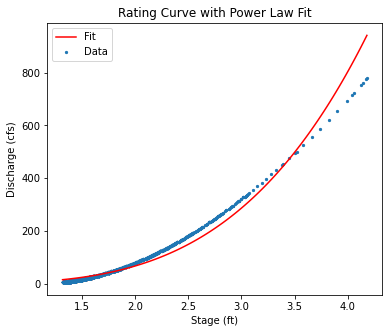

In [10]:
## Q2.2 code here ##

# import scipy
from scipy.optimize import curve_fit

# define general power law
def func(x, a, b):
    return a*(x**b)

### your code below here ###

# removing NaNs
mask = (~np.isnan(stage)) & (~np.isnan(discharge))
stage_clean = stage[mask]
discharge_clean = discharge[mask]

# fit curve
params, _ = curve_fit(func, stage_clean, discharge_clean)

a, b = params
print(f"a = {a}, b = {b}")

#it is by assuming Q = a * h^b

# plot fitted curve
h_fit = np.linspace(min(stage_clean), max(stage_clean), 100)
Q_fit = func(h_fit, a, b)

fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(stage_clean, discharge_clean, s=5, label='Data')
ax.plot(h_fit, Q_fit, color='red', label='Fit')
ax.set_title('Rating Curve with Power Law Fit')
ax.set_xlabel('Stage (ft)')
ax.set_ylabel('Discharge (cfs)')
ax.legend()


`Q2.3 At later, very high stream stages, the power-law model (red curve) begins to deviate more from the obsserved data. As shown on the plot, the fitted curve is overestimating the discharge at large stage/height values. This is due to the fact that simple power-law relationship assumes a constant static channel geometry and the river flow behavior. However, it might not be always true. For example, the river may overflow its banks and enter the nearby floodplain, channel geomtry changes a lot, roughness can increase due to vegetation, or backwater effects if it is going to be subcritical flow. So, such events can distort the simple assumptions of the fit curve. Thus, while power-law model was closely capturing the actual data, it deviates from the data in later higher stages because of certain more complex hydraulic effects in nature.`

### Q3 — Manning equation and channel velocity

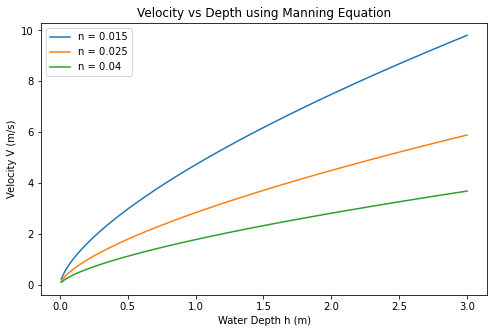

In [11]:
# let's compare the how the velocity changes over different h values
# over two different types of canals

# first define function to obtain velocity (same as above, in notebook)
def mannings(S_0,h,n):
    V = np.sqrt(S_0)*h**(2./3.)/n
    return V

### your code below here ###

# depth range (m)
h = np.linspace(0.01, 3, 100)  # avoiding zero to prevent issues

# estimated slope
S0 = 0.005 #5 unit of vertical drop per 1000 unit of horizontality

# different Manning n values
n_values = [0.015, 0.025, 0.040]

# plot
fig, ax = plt.subplots(figsize=(8,5))

for n in n_values:
    V = mannings(S0, h, n)
    ax.plot(h, V, label=f'n = {n}')

ax.set_xlabel('Water Depth h (m)')
ax.set_ylabel('Velocity V (m/s)')
ax.set_title('Velocity vs Depth using Manning Equation')
ax.legend()


`Q3.2 The slope S for Stony Brook was estimated using looking at its trajectory and pictures from Google Maps. By observing the Princeton terrain to be relatively flat, low relief, Stony Brook slope should have a small slope. So, I estimated it to be 0.005. I believe this is consistent with a natural stream in a semi-forested area as I noticed from its paths across NJ.  `


`The Manning’s roughness coefficient n was estimated using reference tables for different channels. Again by looking at visual pictures on Google Map, it seems like Stony Brook has moderate vegetation, natural bed, and some irregularity. So, based on this, following values of n were selected: `

`n=0.015: smooth channel;
n=0.025: typical natural stream;
n=0.040: rough channel with substantial vegetation;`

`Q3.3 The plot shows that: Firstly, the velocity increases with water depth, as expected. It is consistent with the Manning equation where h ^ 2/3 is on the numerator, being directly proportional to the velocity value. So, it means that deeper the water is, less resistance it experiences, so moves faster. Secondly, again understanding from formula, the velocity decreases as Manning's n roughness coefficient increases. Since n is on denominator, it is inversely proportional. Rougher the channels, slower the flow due to increased friction between water and the surface.`

`I also tried to compare these results with previous discharge data of USGS that we used for Stony Brook. The formula is V = Q / A. Cross sectional area with narrow width, A = b x h, is 10 x 1 = 10 m^2 for generally in average. If I assume flow to be around 40 cfs when there is no huge precipitation, 1.1327 m^3 / s. Calculating V gives us = 0.1-0.12 m/s. It is within the values from the plots, inclined towards shallower water depth, and rougher channel.`

`Here it is worth noting that cross-sectional area, in addition to water depth, changes across different parts of river, so the values are dynamic. Overall, the model captures both conceptual and physical behavior - deeper and smoother channels produce faster flow, while shallower and rougher channels produce slower flow.`


### Q4 — Analytical and numerical kinematic-wave solutions

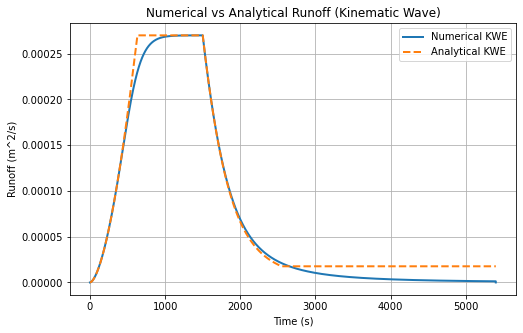

In [12]:
# import root finding library
from scipy.optimize import newton

# use the following values to get head distribution and runoff

# length (m) and slope (m/m) of domain
L = 100
s0 = 0.05

# mannings coefficient (s/(m^(1/3)))
n = 0.02

# rainfall duration (s) and rate (m/s)
rd = 1500
rr = 0.0000027

# dt (s) and dx (m)
dt = 0.3
dx = 10

# if you have the "run_num" cell in the kernel, you can simply call
# it here without re-writing the function

### your code below here ###

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton

#numerical
runoff_num, head, time = run_num(L, s0, n, rd, rr, dt, dx)

#analytical
tc = (L * n / (np.sqrt(s0) * rr**(2/3)))**(3/5)
tr = rd

# constant for recession equation
C = rr * (5/3) * (np.sqrt(s0)/n)**(3/5)


q_ana = np.zeros_like(time)

for i, t in enumerate(time):

    # 1.
    if t <= tc:
        q_ana[i] = (np.sqrt(s0)/n) * (rr * t)**(5/3)

    # 2. 
    elif t <= tr:
        q_ana[i] = rr * L

    # 3. 
    else:

        def safe_q_power(q):
            return np.power(np.maximum(q, 1e-10), 2/5)

        def f(q):
            q = np.maximum(q, 1e-10)
            return q - (rr * L - C * safe_q_power(q) * (t - tr))

        q_guess = max(rr * L, 1e-6)

        try:
            q_ana[i] = newton(f, q_guess, maxiter=100)
        except RuntimeError:
            q_ana[i] = q_ana[i-1]  # to prevent error due to negative/NaN

        
fig, ax = plt.subplots(figsize=(8,5))

ax.plot(time, runoff_num, label="Numerical KWE", linewidth=2)
ax.plot(time, q_ana, '--', label="Analytical KWE", linewidth=2)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Runoff (m^2/s)")
ax.set_title("Numerical vs Analytical Runoff (Kinematic Wave)")
ax.legend()
ax.grid(True)

plt.show()

`Q4.2 The numerical and analytical solutions show generally a very similar behavior throughout the time period, such as same trend of rising runoff during rainfall, a steady-state plateau, and the recession after rainfall stops. However, there are small differences at each step between two curves, especially during steady-state and later stages of recession. The numerical solution has slight smoothing compared to analytical KWE. The method of considering both time and space steps into specific grids is causing numerical one to have slightly delayed peak runoff, smoother transitions between 3 phases, and also small deviations during the recession (post-3000 s). The analytical KWE assumes simply a more idealized contious conditions for both space and time, using already established wave equations, so it shows sharper changes between phases. Overall, both solutions agree well, implying that the numerical solution is more stable and consistent with the theoretical KW behavior. `


`Q4.3 The analytical KWE solution and the linear reservoir solution from HW1 are similar. Both describe how water storage translates into outflow over time, considering the phases before during after rain. So, both of them show rising and recession behavior controlled by input and system response. However, there are couple of differences. Linear Reservoir analytical model does not consider spatial dimension - it is a lumped system. It is built on a simple ODE: dS / dt = P - Q, where Q = kS. k was related to T star, and equation was divided into two - during rain and after rain (t, t-tr). We are assuming a linear relationship between the storage S and outflow Q, through coefficient k. The graph exibits an exponential decay.`

`I believe that analytical solution for kinematic wave is not a simple ODE, but more complex nonlinear PDE. Flow depends on many factors like depth and slope. Q is proportional to h ^ 5/3. So, they do not necessarily produce an exponential graph, and also includes the behaviors of waves when plotting the graph. Simply, linear reservoir model is a simplified concept of catchment storage as a one-box model, while the kinematic wave model represents physical flow dynamics and spatial transport of the water. 


## AI-use disclosure

`I used chatgpt to understand the use of SciPy better in automatically approximating values for me in Q4. I also had to use it to debug a code, that doesn't show error when negative or NaN values appear, in Q4.`